# Assignment 1 - Data Privacy

Covers all five tasks: preprocessing, masking (generalization, rank swapping, noise), disclosure risk, generic info loss, and specific info loss via classification.

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

## 1. Data Preprocessing

### 1.1 Loading the dataset
The Adult dataset has 14 attributes plus income as the target. Missing values are marked with '?' — I just drop those rows.

In [2]:
columns = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]

df = pd.read_csv("adult.data", header=None, names=columns, skipinitialspace=True, na_values="?")

print(f"Dataset shape before cleaning: {df.shape}")
print(f"Missing values per column:\n{df.isnull().sum()}")

Dataset shape before cleaning: (32561, 15)
Missing values per column:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [3]:
# drop rows with missing values
df = df.dropna().reset_index(drop=True)
print(f"Dataset shape after dropping missing: {df.shape}")
df.head()

Dataset shape after dropping missing: (30162, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### 1.2 Encoding categorical attributes
LabelEncoder on each categorical column. I went with label encoding instead of one-hot to keep the column count low — makes the distance calculations in task 3 simpler too.

In [4]:
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
print(f"Categorical columns: {cat_cols}")

df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})

encoders = {}
for col in cat_cols:
    if col == "income":
        continue
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

print("\nEncoded dataset:")
df.head()

Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']

Encoded dataset:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,5,77516,9,13,4,0,1,4,1,2174,0,40,38,0
1,50,4,83311,9,13,2,3,0,4,1,0,0,13,38,0
2,38,2,215646,11,9,0,5,1,4,1,0,0,40,38,0
3,53,2,234721,1,7,2,5,0,2,1,0,0,40,38,0
4,28,2,338409,9,13,2,9,5,2,0,0,0,40,4,0


### 1.3 Normalization
Everything gets scaled to [0,1] with MinMaxScaler so that distance calculations later aren't dominated by high-range columns like fnlwgt.

In [5]:
feature_cols = [c for c in df.columns if c != "income"]
target = df["income"].copy()

scaler = MinMaxScaler()
df_normalized = pd.DataFrame(scaler.fit_transform(df[feature_cols]), columns=feature_cols)

original_data = df_normalized.copy()

print(f"Normalized data shape: {df_normalized.shape}")
print(f"\nMin values:\n{df_normalized.min()}")
print(f"\nMax values:\n{df_normalized.max()}")

Normalized data shape: (30162, 14)

Min values:
age               0.0
workclass         0.0
fnlwgt            0.0
education         0.0
education_num     0.0
marital_status    0.0
occupation        0.0
relationship      0.0
race              0.0
sex               0.0
capital_gain      0.0
capital_loss      0.0
hours_per_week    0.0
native_country    0.0
dtype: float64

Max values:
age               1.0
workclass         1.0
fnlwgt            1.0
education         1.0
education_num     1.0
marital_status    1.0
occupation        1.0
relationship      1.0
race              1.0
sex               1.0
capital_gain      1.0
capital_loss      1.0
hours_per_week    1.0
native_country    1.0
dtype: float64


In [6]:
df_normalized.describe()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
count,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000,30162.000000
mean,0.293670,0.366554,0.119669,0.688918,0.608087,0.430022,0.458450,0.283668,0.919651,0.675685,0.010920,0.020288,0.407462,0.909564
std,0.179927,0.158987,0.071827,0.254153,0.170000,0.249669,0.309967,0.320268,0.208677,0.468126,0.074064,0.092814,0.122245,0.152634
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.150685,0.333333,0.070607,0.600000,0.533333,0.333333,0.153846,0.000000,1.000000,0.000000,0.000000,0.000000,0.397959,0.950000
50%,0.273973,0.333333,0.111940,0.733333,0.600000,0.333333,0.461538,0.200000,1.000000,1.000000,0.000000,0.000000,0.397959,0.950000
75%,0.410959,0.333333,0.152188,0.800000,0.800000,0.666667,0.692308,0.600000,1.000000,1.000000,0.000000,0.000000,0.448980,0.950000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2. Masking Methods

Three methods: generalization on age/education_num, rank swapping, and Laplace noise. Four parameter settings each, then I pick the one that balances risk and utility best.

### 2.1 Heuristic Generalization

Generalization here just means rounding the normalized values to fewer decimal places. Lower depth = more aggressive rounding = bigger groups of indistinguishable records. I apply it to age and education_num since those are the obvious quasi-identifiers.

One thing I realized is that this only touches 2 out of 14 columns, so the other 12 are still fully intact for an attacker to use. That limits how much risk reduction you can actually get.

In [7]:
def generalize(df, depth_dict):
    """Round specified columns to given decimal places."""
    result = df.copy()
    for col, depth in depth_dict.items():
        if col in result.columns:
            result[col] = np.round(result[col], decimals=depth)
    return result

In [8]:
gen_params = [
    {"age": 0, "education_num": 0},
    {"age": 1, "education_num": 1},
    {"age": 1, "education_num": 2},
    {"age": 2, "education_num": 2},
]

gen_results = {}
for i, params in enumerate(gen_params):
    masked = generalize(original_data, params)
    gen_results[i] = masked
    unique_age = masked["age"].nunique()
    unique_edu = masked["education_num"].nunique()
    print(f"Params {params}: unique age values = {unique_age}, unique education_num values = {unique_edu}")

Params {'age': 0, 'education_num': 0}: unique age values = 2, unique education_num values = 2
Params {'age': 1, 'education_num': 1}: unique age values = 11, unique education_num values = 11
Params {'age': 1, 'education_num': 2}: unique age values = 11, unique education_num values = 16
Params {'age': 2, 'education_num': 2}: unique age values = 72, unique education_num values = 16


### 2.2 Rank Swapping

Sort each column by rank, then swap values between records within p% rank distance of each other. Higher p = more swapping. Unlike generalization this hits all 14 columns, so it should actually reduce risk across the board.

The nice property here is that the marginal distribution of each column stays exactly the same — we're just rearranging values, not changing them. Correlations between columns do get messed up though.

In [9]:
def rank_swap(df, p):
    """Swap values within p% rank distance, column by column."""
    result = df.copy()
    n = len(result)
    max_swap_dist = max(int(n * p / 100), 1)

    for col in result.columns:
        values = result[col].values.copy()
        sorted_indices = np.argsort(values)
        swapped = np.zeros(n, dtype=bool)

        for i in range(n):
            idx = sorted_indices[i]
            if swapped[i]:
                continue
            high = min(i + max_swap_dist, n - 1)

            candidates = []
            for j in range(i + 1, high + 1):
                if not swapped[j]:
                    candidates.append(j)

            if len(candidates) == 0:
                continue

            partner_rank = candidates[np.random.randint(len(candidates))]
            partner_idx = sorted_indices[partner_rank]

            values[idx], values[partner_idx] = values[partner_idx], values[idx]
            swapped[i] = True
            swapped[partner_rank] = True

        result[col] = values

    return result

In [10]:
np.random.seed(42)

rs_params = [2, 5, 10, 20]

rs_results = {}
for p in rs_params:
    masked = rank_swap(original_data, p)
    rs_results[p] = masked
    mad = np.mean(np.abs(masked.values - original_data.values))
    print(f"p = {p}%: mean absolute difference from original = {mad:.6f}")

p = 2%: mean absolute difference from original = 0.009684
p = 5%: mean absolute difference from original = 0.022700
p = 10%: mean absolute difference from original = 0.041270
p = 20%: mean absolute difference from original = 0.074148


### 2.3 Noise Addition (Laplace)

Add Laplace noise to every value and clip to [0,1]. I went with Laplace over Gaussian since it has heavier tails — outlier records (the ones most likely to be re-identified) get bigger perturbations more often. The scale parameter controls noise magnitude.

In [11]:
def add_laplace_noise(df, scale):
    """Add Laplace noise, clip to [0,1]."""
    result = df.copy()
    noise = np.random.laplace(loc=0, scale=scale, size=result.shape)
    result = result + noise
    result = result.clip(0, 1)
    return result

In [12]:
np.random.seed(42)

noise_params = [0.01, 0.05, 0.1, 0.2]

noise_results = {}
for scale in noise_params:
    masked = add_laplace_noise(original_data, scale)
    noise_results[scale] = masked
    mad = np.mean(np.abs(masked.values - original_data.values))
    print(f"scale = {scale}: mean absolute difference from original = {mad:.6f}")

scale = 0.01: mean absolute difference from original = 0.008249
scale = 0.05: mean absolute difference from original = 0.039972
scale = 0.1: mean absolute difference from original = 0.077175
scale = 0.2: mean absolute difference from original = 0.140649


## 3. Disclosure Risk Assessment

For each masked record, find its nearest neighbor in the original data (Euclidean distance). If the nearest neighbor is the actual same record, that's a successful re-identification. Disclosure risk = fraction of correctly linked records.

I sample 3000 records instead of using the full 30k because the full distance matrix would be huge (~7GB).

In [13]:
from scipy.spatial.distance import cdist


def disclosure_risk(original, masked, sample_size=3000):
    """Distance-based record linkage on a random sample."""
    n = len(original)
    if sample_size > n:
        sample_size = n

    np.random.seed(123)
    sample_idx = np.random.choice(n, size=sample_size, replace=False)

    orig_sample = original.iloc[sample_idx].values
    mask_sample = masked.iloc[sample_idx].values

    distances = cdist(mask_sample, orig_sample, metric="euclidean")
    nearest = np.argmin(distances, axis=1)

    correct_links = np.sum(nearest == np.arange(sample_size))
    risk = correct_links / sample_size

    return risk

In [14]:
# compute disclosure risk for all masking methods and parameter settings

print("=== Generalization ===")
gen_risks = {}
for i, params in enumerate(gen_params):
    risk = disclosure_risk(original_data, gen_results[i])
    gen_risks[i] = risk
    print(f"  Params {params}: risk = {risk:.4f} ({risk*100:.1f}%)")

print("\n=== Rank Swapping ===")
rs_risks = {}
for p in rs_params:
    risk = disclosure_risk(original_data, rs_results[p])
    rs_risks[p] = risk
    print(f"  p = {p}%: risk = {risk:.4f} ({risk*100:.1f}%)")

print("\n=== Noise Addition ===")
noise_risks = {}
for scale in noise_params:
    risk = disclosure_risk(original_data, noise_results[scale])
    noise_risks[scale] = risk
    print(f"  scale = {scale}: risk = {risk:.4f} ({risk*100:.1f}%)")

=== Generalization ===
  Params {'age': 0, 'education_num': 0}: risk = 0.3193 (31.9%)
  Params {'age': 1, 'education_num': 1}: risk = 0.9653 (96.5%)
  Params {'age': 1, 'education_num': 2}: risk = 0.9653 (96.5%)
  Params {'age': 2, 'education_num': 2}: risk = 1.0000 (100.0%)

=== Rank Swapping ===
  p = 2%: risk = 0.8873 (88.7%)
  p = 5%: risk = 0.6627 (66.3%)
  p = 10%: risk = 0.3583 (35.8%)
  p = 20%: risk = 0.1027 (10.3%)

=== Noise Addition ===
  scale = 0.01: risk = 0.9743 (97.4%)
  scale = 0.05: risk = 0.6827 (68.3%)
  scale = 0.1: risk = 0.3343 (33.4%)
  scale = 0.2: risk = 0.0970 (9.7%)


### Select best parameters

I want risk below ~35% without completely destroying the data. For generalization only the most aggressive setting actually does anything (because only 2 columns change). For rank swapping and noise I pick the setting around 33-36% risk.

In [15]:
# I'll pick a balanced parameter for each method and use those going forward
# For generalization: only the most aggressive setting (depth 0) actually reduces risk,
# because generalization only affects 2 out of 14 columns. The other 12 stay untouched
# so the attacker can still link records through them.
# For rank swapping and noise: I pick the setting where risk drops to around 33-36%.

best_gen_idx = 0  # depth {age:0, education_num:0} - only setting that really reduces risk
best_rs_p = 10  # 10% rank swap distance
best_noise_scale = 0.1  # moderate-high noise

masked_gen = gen_results[best_gen_idx]
masked_rs = rs_results[best_rs_p]
masked_noise = noise_results[best_noise_scale]

print(f"Selected generalization params: {gen_params[best_gen_idx]}, risk = {gen_risks[best_gen_idx]:.4f}")
print(f"Selected rank swapping p: {best_rs_p}%, risk = {rs_risks[best_rs_p]:.4f}")
print(f"Selected noise scale: {best_noise_scale}, risk = {noise_risks[best_noise_scale]:.4f}")

Selected generalization params: {'age': 0, 'education_num': 0}, risk = 0.3193
Selected rank swapping p: 10%, risk = 0.3583
Selected noise scale: 0.1, risk = 0.3343


## 4. Generic Information Loss

Using the formula from the assignment:

$$IL(o, m^s) = \frac{1}{|V|} \sum_i \sum_v \frac{(o_{iv} - m^s_{iv})^2}{\bar{o}_v}$$

Also computing MSE as a secondary check.

In [16]:
def information_loss(original, masked):
    """IL formula from the assignment + MSE."""
    o = original.values
    m = masked.values
    n_vars = o.shape[1]

    o_means = np.mean(o, axis=0)
    o_means_safe = np.where(o_means == 0, 1e-10, o_means)

    squared_diffs = (o - m) ** 2
    il = (1 / n_vars) * np.sum(squared_diffs / o_means_safe)
    mse = np.mean(squared_diffs)

    return il, mse

In [17]:
# compute information loss for all methods with all parameters
print("=== Generalization ===")
gen_il = {}
for i, params in enumerate(gen_params):
    il, mse = information_loss(original_data, gen_results[i])
    gen_il[i] = (il, mse)
    print(f"  Params {params}: IL = {il:.4f}, MSE = {mse:.6f}")

print("\n=== Rank Swapping ===")
rs_il = {}
for p in rs_params:
    il, mse = information_loss(original_data, rs_results[p])
    rs_il[p] = (il, mse)
    print(f"  p = {p}%: IL = {il:.4f}, MSE = {mse:.6f}")

print("\n=== Noise Addition ===")
noise_il = {}
for scale in noise_params:
    il, mse = information_loss(original_data, noise_results[scale])
    noise_il[scale] = (il, mse)
    print(f"  scale = {scale}: IL = {il:.4f}, MSE = {mse:.6f}")

=== Generalization ===
  Params {'age': 0, 'education_num': 0}: IL = 1132.6028, MSE = 0.016002
  Params {'age': 1, 'education_num': 1}: IL = 8.2396, MSE = 0.000103
  Params {'age': 1, 'education_num': 2}: IL = 6.1186, MSE = 0.000060
  Params {'age': 2, 'education_num': 2}: IL = 0.0815, MSE = 0.000001

=== Rank Swapping ===
  p = 2%: IL = 1257.6682, MSE = 0.002438
  p = 5%: IL = 2160.9758, MSE = 0.006433
  p = 10%: IL = 3366.7488, MSE = 0.013036
  p = 20%: IL = 4691.6153, MSE = 0.027186

=== Noise Addition ===
  scale = 0.01: IL = 44.6412, MSE = 0.000164
  scale = 0.05: IL = 1062.8471, MSE = 0.003834
  scale = 0.1: IL = 4169.8176, MSE = 0.014188
  scale = 0.2: IL = 14983.1889, MSE = 0.045599


In [18]:
# info loss for the selected best parameters
il_gen, mse_gen = information_loss(original_data, masked_gen)
il_rs, mse_rs = information_loss(original_data, masked_rs)
il_noise, mse_noise = information_loss(original_data, masked_noise)

print("Information loss for selected parameters:")
print(f"  Generalization: IL = {il_gen:.4f}, MSE = {mse_gen:.6f}")
print(f"  Rank Swapping:  IL = {il_rs:.4f}, MSE = {mse_rs:.6f}")
print(f"  Noise Addition: IL = {il_noise:.4f}, MSE = {mse_noise:.6f}")

Information loss for selected parameters:
  Generalization: IL = 1132.6028, MSE = 0.016002
  Rank Swapping:  IL = 3366.7488, MSE = 0.013036
  Noise Addition: IL = 4169.8176, MSE = 0.014188


## 5. Specific Information Loss (Classification Utility)

Train a Random Forest on the masked data, predict income, compare accuracy to the original. Same 70/30 split across all experiments so the comparison is fair.

In [19]:
def evaluate_classification(X, y, method_name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    clf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)

    print(f"  {method_name}:")
    print(f"    Accuracy:  {acc:.4f}")
    print(f"    Precision: {prec:.4f}")
    print(f"    Recall:    {rec:.4f}")

    return acc, prec, rec

In [20]:
# first establish a baseline with the original (unmasked) data
print("=== Baseline (Original Data) ===")
acc_orig, prec_orig, rec_orig = evaluate_classification(original_data, target, "Original")

print("\n=== Generalization ===")
acc_gen, prec_gen, rec_gen = evaluate_classification(masked_gen, target, "Generalization")

print("\n=== Rank Swapping ===")
acc_rs, prec_rs, rec_rs = evaluate_classification(masked_rs, target, "Rank Swapping")

print("\n=== Noise Addition ===")
acc_noise, prec_noise, rec_noise = evaluate_classification(masked_noise, target, "Noise Addition")

=== Baseline (Original Data) ===
  Original:
    Accuracy:  0.8611
    Precision: 0.7825
    Recall:    0.6119

=== Generalization ===
  Generalization:
    Accuracy:  0.8567
    Precision: 0.7807
    Recall:    0.5897

=== Rank Swapping ===
  Rank Swapping:
    Accuracy:  0.8225
    Precision: 0.7001
    Recall:    0.5018

=== Noise Addition ===
  Noise Addition:
    Accuracy:  0.7939
    Precision: 0.6418
    Recall:    0.3890


## Summary of Results

In [21]:
# put everything in a nice summary table
summary = pd.DataFrame(
    {
        "Method": ["Original (baseline)", "Generalization", "Rank Swapping", "Noise Addition"],
        "Parameters": ["-", f"depth: {gen_params[best_gen_idx]}", f"p = {best_rs_p}%", f"scale = {best_noise_scale}"],
        "Disclosure Risk": [1.0, gen_risks[best_gen_idx], rs_risks[best_rs_p], noise_risks[best_noise_scale]],  # original data has 100% linkage
        "Info Loss (IL)": [0.0, il_gen, il_rs, il_noise],
        "MSE": [0.0, mse_gen, mse_rs, mse_noise],
        "Accuracy": [acc_orig, acc_gen, acc_rs, acc_noise],
        "Precision": [prec_orig, prec_gen, prec_rs, prec_noise],
        "Recall": [rec_orig, rec_gen, rec_rs, rec_noise],
    }
)

summary

,Method,Parameters,Disclosure Risk,Info Loss (IL),MSE,Accuracy,Precision,Recall
0,Original (baseline),-,1.000000,0.000000,0.000000,0.861090,0.782510,0.611901
1,Generalization,"depth: {'age': 0, 'education_num': 0}",0.319333,1132.602834,0.016002,0.856669,0.780717,0.589698
2,Rank Swapping,p = 10%,0.358333,3366.748767,0.013036,0.822522,0.700124,0.501776
3,Noise Addition,scale = 0.1,0.334333,4169.817563,0.014188,0.793900,0.641758,0.388988


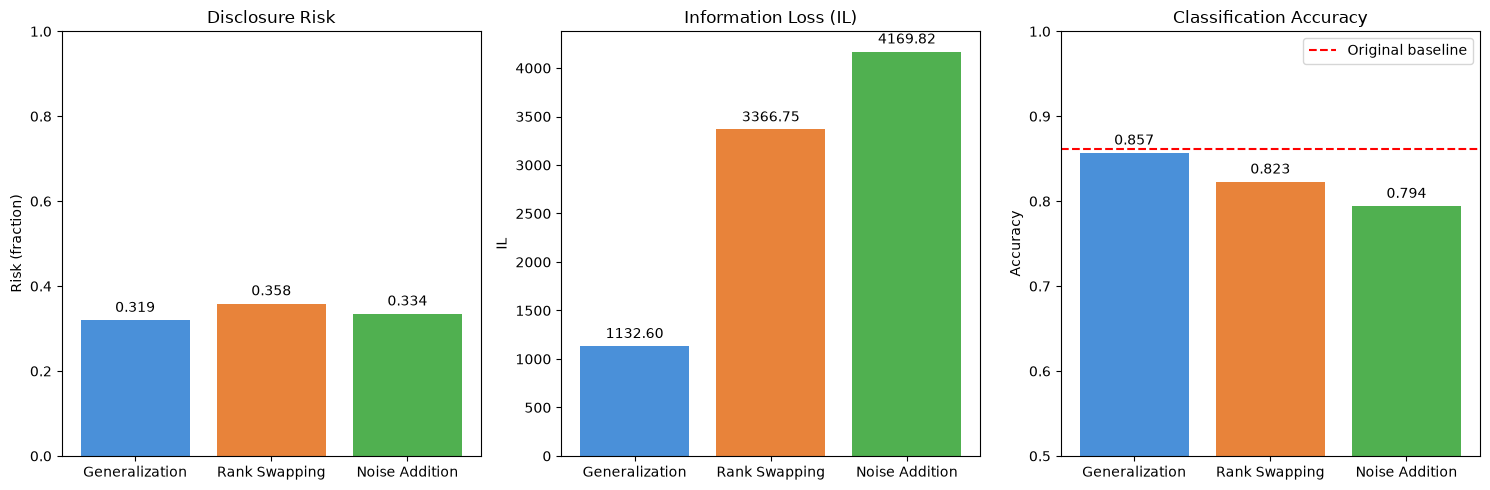

In [22]:
# visualization: bar chart comparing the methods
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

methods = ["Generalization", "Rank Swapping", "Noise Addition"]
risks = [gen_risks[best_gen_idx], rs_risks[best_rs_p], noise_risks[best_noise_scale]]
ils = [il_gen, il_rs, il_noise]
accs = [acc_gen, acc_rs, acc_noise]

colors = ["#4a90d9", "#e8833a", "#50b050"]

axes[0].bar(methods, risks, color=colors)
axes[0].set_title("Disclosure Risk")
axes[0].set_ylabel("Risk (fraction)")
axes[0].set_ylim(0, 1)
for i, v in enumerate(risks):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center")

axes[1].bar(methods, ils, color=colors)
axes[1].set_title("Information Loss (IL)")
axes[1].set_ylabel("IL")
for i, v in enumerate(ils):
    axes[1].text(i, v + max(ils) * 0.02, f"{v:.2f}", ha="center")

axes[2].bar(methods, accs, color=colors)
axes[2].axhline(y=acc_orig, color="red", linestyle="--", label="Original baseline")
axes[2].set_title("Classification Accuracy")
axes[2].set_ylabel("Accuracy")
axes[2].set_ylim(0.5, 1.0)
axes[2].legend()
for i, v in enumerate(accs):
    axes[2].text(i, v + 0.01, f"{v:.3f}", ha="center")

plt.tight_layout()
plt.savefig("results_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Discussion

Generalization was kind of disappointing honestly. Since it only changes 2 columns, the other 12 are still there for an attacker to match on. Even rounding age and education to basically binary values only got risk down to 32%. You'd need to generalize way more columns for this to actually work, but then the data would be pretty useless. The upside is that accuracy barely dropped (0.857 vs 0.861) — but that's expected when you're only touching 2 features.

Rank swapping worked better than I expected. With p=10% the risk drops to 36% and accuracy is still at 0.823, which is decent. It keeps the marginal distributions intact since values just get shuffled around within each column. The tradeoff is that correlations between columns get broken, which is why the classifier takes a hit — but not as bad as with noise.

Noise addition gives similar risk reduction (33%) but hurts accuracy more, especially recall which drops from 0.61 to 0.39. So the classifier trained on noisy data basically misses a lot of the >50K income people. I think this is because noise shifts values in all directions uniformly, while rank swapping at least keeps values within a reasonable range of where they were.

Overall I'd go with rank swapping for this dataset. It has the best balance between risk and keeping the data useful for classification. Noise might be better if you care about formal privacy guarantees (since Laplace noise ties into differential privacy) but for practical utility rank swapping wins here.